# Modelo de faixas de atraso de voos

Continuação do `02_insights_ml.ipynb` (situação-problema **A**): prever **em que faixa de atraso** a partida de um voo vai cair.

| Decisão | Escolha | Por quê |
|---|---|---|
| Tarefa | Classificação em 4 faixas: até 15 min, 15–30, 30–60, > 60 min | O atraso em minutos tem cauda longa (alguns voos com 10 h+), o que estraga uma regressão; faixas respondem a pergunta prática e preservam a gravidade |
| Horizontes | **Véspera** (meia-noite do dia do voo) e **3 h antes** da partida | Cada horizonte só usa o que já se sabe naquele instante, senão o modelo "olha o futuro" |
| Algoritmo | Gradient boosting em árvores (`HistGradientBoostingClassifier`) | Dados tabulares mistos, interações não lineares (trovoada × hub × horário), aceita valores vazios e categorias nativamente, rápido em 500 mil linhas |
| Validação | Temporal: busca de hiperparâmetros com janela crescente em jan–set; teste final em out–dez | Dividir aleatoriamente deixaria voos do mesmo dia no treino e no teste |
| Alarme falso | Aceitável | O modelo é treinado sem pesos (probabilidades fiéis) e a **decisão** é calibrada para privilegiar o recall dos atrasos |
| Cancelados | Fora | Não têm horário real de partida |

O código das variáveis está em `module_decea/features.py` e o de treino/avaliação em `module_decea/modelagem.py`.

## 1. Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from module_decea import features as F
from module_decea import modelagem as M

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

AZUL, LARANJA, CINZA, TINTA2, GRADE, FUNDO = "#2a78d6", "#eb6834", "#c3c2b7", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "axes.edgecolor": CINZA, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
})

## 2. Dados e alvo

Voos regulares domésticos realizados em 2025 saindo dos 10 aeroportos com METAR (VRA/ANAC + METAR/IEM, mesmos arquivos do notebook 02).

In [2]:
t0 = time.time()
voos = F.carregar_voos()
metar = F.carregar_metar_horario()
X3, y, info = F.montar("3h", voos, metar)
Xv, _, _ = F.montar("vespera", voos, metar)
meses = info["partida_prev"].dt.month.values
treino, teste = meses <= 9, meses >= 10
print(f"{len(y):,} voos realizados | treino jan–set {treino.sum():,} | teste out–dez {teste.sum():,} | {time.time() - t0:.0f}s"
      .replace(",", "."))
print(f"variáveis: véspera {Xv.shape[1]} | 3 h antes {X3.shape[1]}")

501.641 voos realizados | treino jan–set 374.530 | teste out–dez 127.111 | 26s
variáveis: véspera 30 | 3 h antes 60


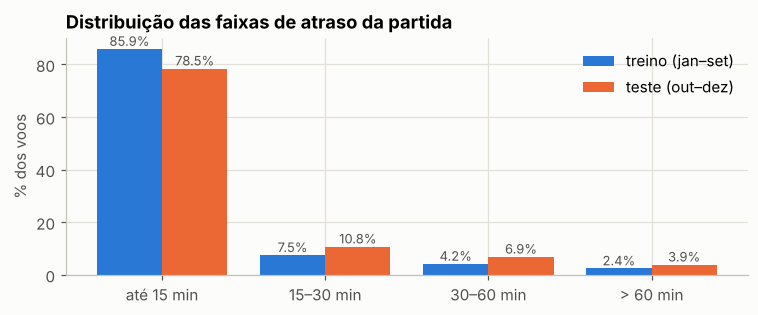

In [3]:
dist = pd.DataFrame({"treino": y[treino].value_counts(normalize=True), "teste": y[teste].value_counts(normalize=True)})
dist.index = F.FAIXAS
fig, ax = plt.subplots(figsize=(8, 2.8))
x = np.arange(len(F.FAIXAS))
ax.bar(x - 0.2, dist["treino"] * 100, 0.4, color=AZUL, label="treino (jan–set)")
ax.bar(x + 0.2, dist["teste"] * 100, 0.4, color=LARANJA, label="teste (out–dez)")
for i, (a, b) in enumerate(zip(dist["treino"], dist["teste"])):
    ax.text(i - 0.2, a * 100, f"{a:.1%}", ha="center", va="bottom", fontsize=8.5, color=TINTA2)
    ax.text(i + 0.2, b * 100, f"{b:.1%}", ha="center", va="bottom", fontsize=8.5, color=TINTA2)
ax.set_xticks(x, F.FAIXAS)
ax.set_ylabel("% dos voos")
ax.set_title("Distribuição das faixas de atraso da partida")
ax.legend(frameon=False)
plt.show()

**Leitura:** 84% dos voos saem com até 15 min de atraso. As três faixas de atraso somam 16%, e a mais grave (> 60 min) é só ~3%. Por isso **acurácia não serve** (dizer sempre "até 15 min" acerta 84%). As métricas usadas são:

- **ROC-AUC / PR-AUC de "atraso > 30 min"** (soma das probabilidades das duas faixas mais altas): medem se o modelo **ordena** bem o risco, sem depender de limiar. O PR-AUC de um chute é a prevalência (~11%).
- **Log loss**: qualidade das probabilidades nas 4 faixas, usada para escolher os hiperparâmetros.
- **F2 macro, recall e precisão de "atraso > 30 min"**: avaliam a **decisão final**. O F2 dá ao recall o dobro do peso da precisão, porque um alarme falso custa pouco.

## 3. Variáveis por horizonte

| Grupo | Exemplos | Véspera | 3 h antes |
|---|---|:-:|:-:|
| Programação | empresa, origem, destino, aeronave, hora, dia da semana, mês, partidas programadas na hora/dia | ✓ | ✓ |
| Calendário | distância até o feriado mais próximo (inclui Carnaval) | ✓ | ✓ |
| Histórico | taxa de atraso do voo e da rota **nos meses anteriores**; o mesmo voo nos últimos 7 dias | ✓ | ✓ |
| Dia anterior | atraso na origem e na rede, IMC/trovoada/rajada na origem | ✓ | ✓ |
| Clima típico | % de IMC e trovoada naquela hora nos 30 dias anteriores (origem e destino) | ✓ | ✓ |
| Clima agora | METAR da origem e do destino 3 h antes + variação nas 3 h anteriores | | ✓ |
| Propagação | % de partidas atrasadas na origem, no destino e na rede nas horas já observáveis; acumulado do dia | | ✓ |

**Cuidados contra vazamento (o modelo não pode ver o futuro):**
- Histórico do voo/rota: só meses anteriores ao do voo (por isso janeiro fica sem histórico).
- Propagação: uma partida programada às 10h só "vira" atrasada > 30 min às 10h30, no mínimo. Só entram horas até 2 h antes do instante de referência.
- O VRA não diz o fuso; os horários estão em Brasília (UTC−3), conforme verificado no notebook 02.

## 4. Baselines

Para saber se o modelo final ganha alguma coisa:

1. **Chute informado:** prevê para todo voo a distribuição das faixas no treino.
2. **Regressão logística** com as variáveis de 3 h (modelo linear, com categorias em one-hot e vazios imputados).
3. **Árvores só com a programação do voo** (sem histórico, clima ou propagação).

In [4]:
resultados = {}

# 1. Chute: proporção de cada faixa no treino
prior = np.tile(y[treino].value_counts(normalize=True).sort_index().values, (teste.sum(), 1))
resultados["chute (proporção do treino)"] = M.metricas(y[teste], prior)

# 2. Regressão logística (amostra de 150 mil voos de treino, para rodar rápido)
cat = F.CAT
num = [c for c in X3.columns if c not in cat]
logit = make_pipeline(
    make_column_transformer(
        (OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat),
        (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num)),
    LogisticRegression(max_iter=500, C=0.5))
amostra = np.random.default_rng(0).choice(np.flatnonzero(treino), 150_000, replace=False)
t0 = time.time()
logit.fit(X3.iloc[amostra], y.iloc[amostra])
resultados["regressão logística (3 h)"] = M.metricas(y[teste], logit.predict_proba(X3[teste]))
print(f"logística: {time.time() - t0:.0f}s")

# 3. Árvores só com a programação
PROG = F.CAT + ["assentos", "hora", "dia_semana", "mes", "dia_mes", "partidas_hora_origem", "partidas_dia_origem",
                "partidas_dia_rede", "dias_ate_feriado", "feriado"]
t0 = time.time()
m_prog = M.hgb(max_iter=300, learning_rate=0.05).fit(X3.loc[treino, PROG], y[treino])
resultados["árvores: só programação"] = M.metricas(y[teste], m_prog.predict_proba(X3.loc[teste, PROG]))
print(f"árvores programação: {time.time() - t0:.0f}s")

pd.DataFrame(resultados).T.iloc[:, :4].round(3)

logística: 48s


árvores programação: 34s


,log_loss,ROC-AUC macro (4 faixas),ROC-AUC atraso>30,PR-AUC atraso>30
chute (proporção do treino),0.761,0.500,0.500,0.108
regressão logística (3 h),0.670,0.726,0.747,0.323
árvores: só programação,0.758,0.640,0.644,0.171


## 5. Escolha de hiperparâmetros (validação temporal)

Janela crescente dentro do treino: treina em jan–jun e valida em jul; treina em jan–jul e valida em ago; treina em jan–ago e valida em set. O teste (out–dez) não é tocado aqui.

A escolha é pelo **log loss** médio. Ele avalia as probabilidades, que é o que o modelo precisa acertar; o limiar de decisão vem depois.

In [5]:
# Duas famílias: árvores mais livres (31 folhas) e mais regularizadas (15 folhas, folhas grandes, metade das variáveis
# por divisão). Na 1ª rodada, 600 iterações e 63 folhas pioraram: o padrão muda ao longo do ano e o modelo complexo decora.
LIVRE = dict(max_leaf_nodes=31, min_samples_leaf=100, l2_regularization=1.0)
REGULARIZADA = dict(max_leaf_nodes=15, min_samples_leaf=1000, l2_regularization=5.0, max_features=0.5)
grade = [dict(learning_rate=0.05, max_iter=it) | fam for it in (150, 300) for fam in (LIVRE, REGULARIZADA)]
Xtr, ytr, mtr = X3[treino].reset_index(drop=True), y[treino].reset_index(drop=True), meses[treino]
t0 = time.time()
busca = M.busca_hiperparametros(Xtr, ytr, mtr, grade)
print(f"busca: {time.time() - t0:.0f}s")
MELHOR = next(g for g in grade if all(busca.loc[0, k] == v for k, v in g.items()))
print("escolhido:", MELHOR)
busca.round(4)

busca: 613s
escolhido: {'learning_rate': 0.05, 'max_iter': 150, 'max_leaf_nodes': 15, 'min_samples_leaf': 1000, 'l2_regularization': 5.0, 'max_features': 0.5}


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,log_loss,log_loss_dp,max_features
0,0.05,150,15,1000,5.0,0.4893,0.0341,0.5
1,0.05,300,15,1000,5.0,0.4903,0.0344,0.5
2,0.05,150,31,100,1.0,0.4904,0.0336,NaN
3,0.05,300,31,100,1.0,0.4929,0.0346,NaN


## 6. Calibrando a decisão: priorizar o recall dos atrasos

O modelo devolve 4 probabilidades por voo. A faixa prevista é a de maior **probabilidade × peso**. Com peso 1 em tudo, o modelo quase nunca prevê atraso, porque "até 15 min" é sempre a faixa mais provável. Pesos maiores nas faixas de atraso significam aceitar mais alarmes falsos em troca de pegar mais atrasos.

Os pesos são escolhidos no **último fold de validação** (modelo treinado em jan–ago, aplicado em set), maximizando o F2 macro. Depois são aplicados sem mudança no teste.

In [6]:
pesos = {}
for nome, X in [("véspera", Xv), ("3 h antes", X3)]:
    tr, va = treino & (meses <= 8), meses == 9
    p_va = M.hgb(**MELHOR).fit(X[tr], y[tr]).predict_proba(X[va])
    pesos[nome], f2 = M.ajustar_pesos(p_va, y[va].values)
    print(f"{nome}: pesos (até 15, 15–30, 30–60, > 60) = {pesos[nome]} | F2 macro na validação = {f2:.3f}")

véspera: pesos (até 15, 15–30, 30–60, > 60) = (1, 6, 12, 12) | F2 macro na validação = 0.326


3 h antes: pesos (até 15, 15–30, 30–60, > 60) = (1, 6, 8, 12) | F2 macro na validação = 0.334


## 7. Modelos finais (treino jan–set, teste out–dez)

In [7]:
modelos, proba = {}, {}
for nome, X in [("véspera", Xv), ("3 h antes", X3)]:
    t0 = time.time()
    modelos[nome] = M.hgb(**MELHOR).fit(X[treino], y[treino])
    proba[nome] = modelos[nome].predict_proba(X[teste])
    resultados[f"árvores: {nome}"] = M.metricas(y[teste], proba[nome], pesos[nome])
    print(f"{nome}: {time.time() - t0:.0f}s")

tab = pd.DataFrame(resultados).T
tab.style.format("{:.3f}").background_gradient(subset=["ROC-AUC atraso>30", "PR-AUC atraso>30"], cmap="Blues")

véspera: 25s


3 h antes: 44s


,log_loss,ROC-AUC macro (4 faixas),ROC-AUC atraso>30,PR-AUC atraso>30,F2 macro,recall atraso>30,precisão atraso>30,erro de no máx. 1 faixa
chute (proporção do treino),0.761,0.500,0.500,0.108,0.237,0.000,nan,0.892
regressão logística (3 h),0.670,0.726,0.747,0.323,0.266,0.079,0.653,0.902
árvores: só programação,0.758,0.640,0.644,0.171,0.238,0.002,0.213,0.892
árvores: véspera,0.692,0.709,0.720,0.260,0.323,0.396,0.247,0.845
árvores: 3 h antes,0.663,0.735,0.754,0.336,0.368,0.314,0.323,0.891


As colunas de **ranking** (log loss, ROC-AUC, PR-AUC) comparam todos os modelos de forma justa. As colunas de **decisão** (F2, recall, precisão, erro de no máximo 1 faixa) só fazem sentido nos dois modelos finais, que têm o limiar calibrado. Os baselines estão com peso 1, então quase nunca preveem atraso.

### 7.1 Desempenho por faixa (modelo de 3 h)

,precisão,recall,F1,voos
até 15 min,86.5%,79.7%,0.830,"99,734"
15–30 min,20.7%,33.1%,0.255,"13,673"
30–60 min,19.4%,18.2%,0.188,"8,756"
> 60 min,18.0%,18.5%,0.182,"4,948"


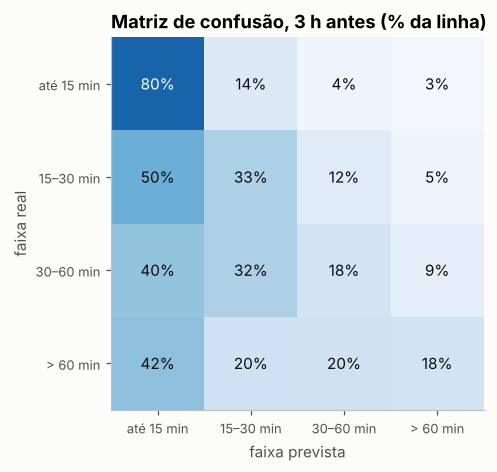

In [8]:
pred3 = M.decidir(proba["3 h antes"], pesos["3 h antes"])
display(M.tabela_por_faixa(y[teste], pred3).style.format({"precisão": "{:.1%}", "recall": "{:.1%}", "F1": "{:.3f}",
                                                          "voos": "{:,.0f}"}))
cm = M.matriz_confusao(y[teste], pred3)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
im = ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm.values[i, j]:.0f}%", ha="center", va="center", fontsize=10,
                color="white" if cm.values[i, j] > 55 else "#0b0b0b")
ax.set_xticks(range(4), F.FAIXAS, rotation=0, fontsize=8.5)
ax.set_yticks(range(4), F.FAIXAS, fontsize=8.5)
ax.set_xlabel("faixa prevista")
ax.set_ylabel("faixa real")
ax.grid(False)
ax.set_title("Matriz de confusão, 3 h antes (% da linha)")
plt.show()

### 7.2 O que o modelo usa (importância por permutação)

Embaralha uma variável por vez no teste e mede quanto o log loss piora. Quanto maior a piora, mais o modelo depende dela. Usa uma amostra de 40 mil voos para rodar rápido.

permutação: 214s


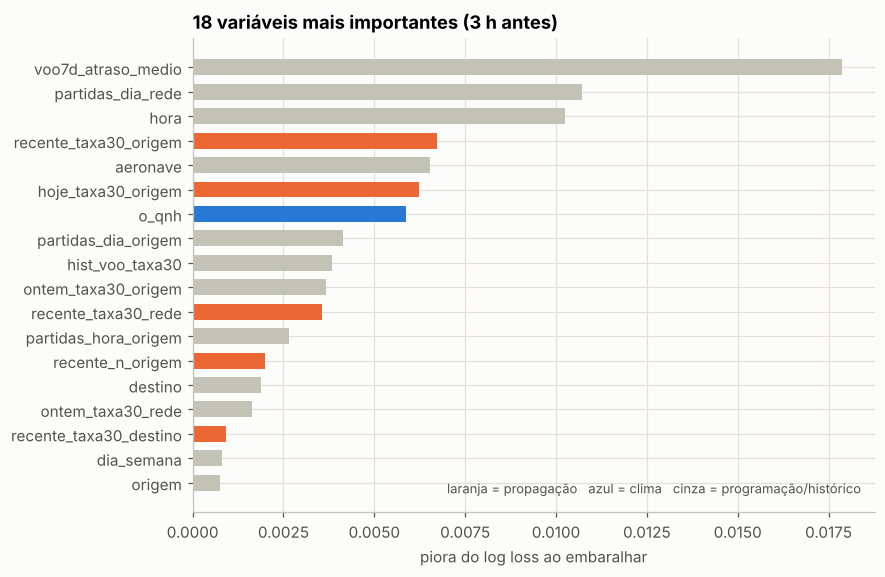

In [9]:
idx = np.random.default_rng(1).choice(np.flatnonzero(teste), 40_000, replace=False)
t0 = time.time()
imp = permutation_importance(modelos["3 h antes"], X3.iloc[idx], y.iloc[idx], scoring="neg_log_loss",
                             n_repeats=3, random_state=0, n_jobs=1)
print(f"permutação: {time.time() - t0:.0f}s")
imp = pd.Series(imp.importances_mean, index=X3.columns).sort_values().tail(18)

GRUPO = {"recente": LARANJA, "hoje": LARANJA, "o_": AZUL, "d_": AZUL, "clim30d": AZUL, "ontem_imc": AZUL,
         "ontem_trovoada": AZUL, "ontem_rajada": AZUL}
cores = [next((c for k, c in GRUPO.items() if n.startswith(k)), CINZA) for n in imp.index]
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(imp.index, imp.values, color=cores, height=0.65)
ax.set_xlabel("piora do log loss ao embaralhar")
ax.set_title("18 variáveis mais importantes (3 h antes)")
ax.text(0.98, 0.04, "laranja = propagação   azul = clima   cinza = programação/histórico", transform=ax.transAxes,
        ha="right", fontsize=8.5, color=TINTA2)
plt.show()

### 7.3 Estabilidade no tempo: PR-AUC de atraso > 30 min por semana do teste

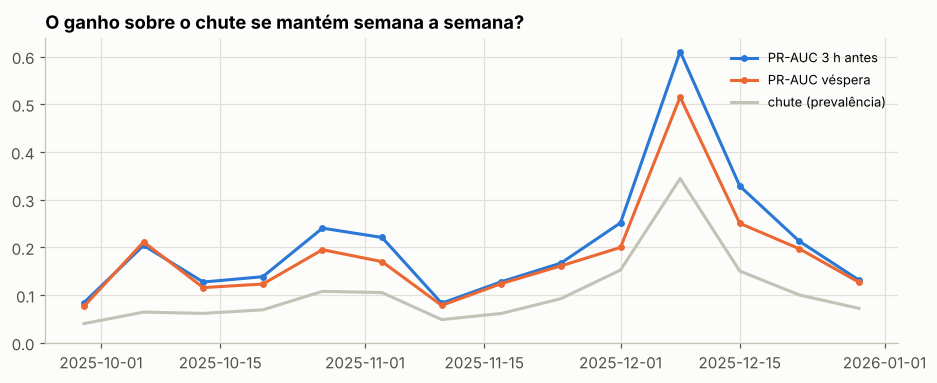

In [10]:
semana = info.loc[teste, "partida_prev"].dt.to_period("W").dt.start_time.values
atr = (y[teste] >= 2).values
linhas = []
for s in np.unique(semana):
    m = semana == s
    linhas.append({"semana": s, "% atraso > 30": atr[m].mean() * 100,
                   **{n: average_precision_score(atr[m], proba[n][m][:, 2:].sum(1)) for n in proba}})
sem = pd.DataFrame(linhas).set_index("semana")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(sem.index, sem["3 h antes"], color=AZUL, linewidth=2, marker="o", markersize=3.5, label="PR-AUC 3 h antes")
ax.plot(sem.index, sem["véspera"], color=LARANJA, linewidth=2, marker="o", markersize=3.5, label="PR-AUC véspera")
ax.plot(sem.index, sem["% atraso > 30"] / 100, color=CINZA, linewidth=2, label="chute (prevalência)")
ax.set_ylim(0, None)
ax.set_title("O ganho sobre o chute se mantém semana a semana?")
ax.legend(frameon=False, fontsize=8.5)
plt.show()

## 8. Conclusões

**Resultado no teste (out–dez 2025, 127 mil voos que o modelo nunca viu):**

| Modelo | ROC-AUC > 30 min | PR-AUC > 30 min | Recall > 30 min | Precisão > 30 min |
|---|---|---|---|---|
| Chute | 0,500 | 0,108 | – | – |
| Árvores, só programação | 0,644 | 0,171 | – | – |
| Regressão logística (3 h) | 0,747 | 0,323 | – | – |
| **Árvores, véspera** | **0,720** | **0,260** | 40% | 25% |
| **Árvores, 3 h antes** | **0,754** | **0,336** | 31% | 32% |

1. **O sinal existe e cresce com o horizonte.** Na véspera o modelo já identifica 2,4× mais atrasos que o chute (PR-AUC 0,26 contra 0,11). Três horas antes chega a 3,1× (0,34), porque passa a ver o clima do momento e a propagação de atrasos na origem.
2. **A programação sozinha explica pouco** (PR-AUC 0,17). O ganho vem do **histórico recente do voo** (atraso médio nos últimos 7 dias, a variável mais importante), do **estado da rede** (atraso recente e acumulado do dia na origem) e, em menor grau, do **clima**. Clima severo é raro, então pesa pouco na média, mas muda muito o risco quando acontece (rajada ≥ 25 kt: 27% de atrasos > 30 min, contra 7,7% na média).
3. **Árvores × regressão logística:** na validação de setembro, as árvores regularizadas venceram com folga (log loss 0,486 contra 0,494). No teste, a vantagem é pequena (0,754 contra 0,747). A busca de hiperparâmetros escolheu o modelo **mais simples** (150 iterações, 15 folhas, folhas com ≥ 1.000 voos): o padrão muda ao longo do ano e um modelo complexo decora o passado.
4. **A decisão é calibrável.** Com pesos de decisão maiores nas faixas de atraso, o modelo troca precisão por recall. O ponto escolhido (F2 em setembro) detecta 31–40% dos atrasos > 30 min com precisão de 25–32%, cerca de 3× a taxa-base. Para pegar mais atrasos, basta subir os pesos e aceitar mais alarmes falsos.
5. **Distinguir as faixas de atraso entre si é o mais difícil:** "> 60 min" tem recall de ~18%. O modelo sabe *que* o risco é alto, mas não *quanto* vai atrasar.
6. **Estável no tempo:** o ganho sobre o chute se mantém semana a semana, inclusive na semana de 8–14/12 (ventania em SP), quando o PR-AUC do modelo de 3 h sobe para 0,61.

**Cuidados:** `o_qnh` (pressão) e `partidas_dia_rede` aparecem entre as importantes, mas podem estar funcionando em parte como "relógio" da estação do ano. Vale testar sem elas.

**Próximos passos:**
- Matrícula da aeronave (não está no VRA) para saber o atraso da perna anterior, que deve ser a variável mais forte.
- TAF (previsão do tempo) via REDEMET, para o modelo da véspera usar previsão em vez de clima típico.
- Modelo ordinal (as faixas têm ordem) e calibração das probabilidades.
- LightGBM e mais anos de dados (2023–2024) para capturar a sazonalidade completa.
